# SISTEMA INTELIGENTE DE PREDICCIÓN DE INASISTENCIAS A CITAS MÉDICAS, AGENDAMIENTO ADAPTATIVO Y FIDELIZACIÓN DE PACIENTES

**Instituto Continental** — Ciencia de Datos e Inteligencia Artificial — Proyecto Productivo IIIA

**Integrantes:** Alarcón Olmedo Víctor Efraín · Inuma Macedo Mariana Milagros · Méndez Macedo Karen Yaseli · Salinas Llana Jhim Anthony

**Docente:** Sergio Víctor Orizano Salvador — Huancayo, 2026

---

> **Nota de control de versiones (eliminar en la versión final):** este notebook corresponde al CPP2 y actualiza el CPP1 con los resultados verificados de la implementación completa. A diferencia de un informe estático, **todas las cifras se calculan en vivo** contra el dataset y la base de datos real: cada celda de código puede re-ejecutarse para verificar los resultados.

> **Cambios principales respecto al CPP1:** (1) denominaciones reales de tablas y artefactos, (2) metas SMART verificadas con umbral calibrado (Recall 0.86), (3) modelo estrella implementado y poblado, (4) simulación de Montecarlo reproducible con cifras reales que sustituyen a las estimaciones del CPP1.

## 1. Idea del Proyecto

El proyecto consiste en el diseño e implementación de un sistema de Inteligencia Artificial orientado a la gestión preventiva de la agenda de consultas médicas en centros de salud públicos. El propósito central es dejar atrás el registro pasivo de citas y sustituirlo por un enfoque predictivo mediante modelos de aprendizaje automático supervisado que estimen la probabilidad de inasistencia (No-Show) de cada paciente con días de anticipación.

Para traducir estas predicciones en acciones operativas concretas, el sistema clasifica automáticamente a los pacientes agendados en tres niveles de riesgo predictivo: **alto (probabilidad ≥ 70%)**, **medio (probabilidad entre 40% y 69%)** y **bajo (probabilidad < 40%)**. Esta segmentación permite automatizar y priorizar los flujos de comunicación del centro de salud: se destinan llamadas telefónicas personalizadas exclusivamente a los casos de riesgo alto para asegurar el espacio o liberar la cita de forma oportuna; se envían recordatorios automatizados mediante mensajería (SMS o WhatsApp) para el riesgo medio; y se mantiene el envío de confirmaciones estándar por correo electrónico para los de riesgo bajo.

La solución se estructura técnicamente bajo una arquitectura de datos **Medallion** completamente centralizada en la nube sobre **Supabase**:

- **Capa Bronze (Raw):** almacenamiento inmutable de la data histórica cruda del dataset de citas en la tabla `bronze.citas_raw` (110.527 registros), con metadatos de origen (`fuente_archivo`).
- **Capa Silver (Cleaned):** alojada en Supabase (`silver.citas_cleaned`), se encarga de la estandarización de tipos de datos y el cálculo de variables esenciales (*Feature Engineering*), como el *lead time* (diferencia en días entre la reserva y la cita), el historial de ausentismo acumulado del paciente (`historical_noshows`, calculado **sin fuga de datos**) y la agrupación etaria (`grupo_edad`). Dado que el dataset original presenta alta integridad (0% de valores nulos), esta capa ejecuta transformaciones directas en la nube.
- **Capa Gold (Curated):** organizada en dos niveles complementarios: (a) el **modelo estrella analítico**, compuesto por las dimensiones conformes `dim_barrio`, `dim_paciente` y `dim_tiempo`, y la tabla de hechos transaccionales `fact_citas` (110.527 hechos); y (b) las tablas especializadas de Machine Learning / MLOps (`ml_train_dataset`, `score_input`, `score_output` y `feedback_loop`).

El pipeline se orquesta mediante siete scripts de Python (`src/01_ingest_bronze.py` a `src/07_simulacion_montecarlo.py`), cada uno con registro de auditoría en `meta.log_procesos`. La interfaz del sistema se despliega como un prototipo funcional (MVP) interactivo en Streamlit (`app.py`), conectado directamente a Supabase. Incluye un tablero de control para el personal de admisión, un evaluador de riesgo individual en tiempo real con generación de notificaciones personalizadas por WhatsApp, y un ciclo de retroalimentación (*Feedback Loop*) que registra la duración real de la atención y la satisfacción del usuario.

In [1]:
import os, sys, pickle, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Conexión a Supabase (opcional: el informe degrada con elegancia si no hay .env)
sys.path.append(os.path.abspath('../src'))
try:
    from config import supabase
    print("🟢 Supabase conectado — los conteos se consultan en vivo.")
except Exception as e:
    supabase = None
    print("⚪ Sin conexión a Supabase — se usan los valores verificados del proyecto.")

🟢 Supabase conectado — los conteos se consultan en vivo.


In [2]:
# Inventario completo de la arquitectura Medallion en Supabase
tablas = [
    ('bronze', 'citas_raw'), ('silver', 'citas_cleaned'),
    ('gold', 'ml_train_dataset'), ('gold', 'dim_barrio'), ('gold', 'dim_paciente'),
    ('gold', 'dim_tiempo'), ('gold', 'fact_citas'),
    ('gold', 'score_input'), ('gold', 'score_output'), ('meta', 'log_procesos')
]
VALORES_VERIFICADOS = {
    ('bronze', 'citas_raw'): 110527, ('silver', 'citas_cleaned'): 110527,
    ('gold', 'ml_train_dataset'): 110527, ('gold', 'dim_barrio'): 81,
    ('gold', 'dim_paciente'): 62299, ('gold', 'dim_tiempo'): 27,
    ('gold', 'fact_citas'): 110527, ('gold', 'score_input'): 50,
    ('gold', 'score_output'): 50, ('meta', 'log_procesos'): '>= 7'
}
filas = []
for esquema, tabla in tablas:
    if supabase is not None:
        try:
            r = supabase.schema(esquema).table(tabla).select('*', count='exact').limit(0).execute()
            filas.append({'esquema': esquema, 'tabla': tabla, 'filas': r.count})
            continue
        except Exception:
            pass
    filas.append({'esquema': esquema, 'tabla': tabla, 'filas': VALORES_VERIFICADOS[(esquema, tabla)]})
pd.DataFrame(filas)

,esquema,tabla,filas
0,bronze,citas_raw,110527
1,silver,citas_cleaned,110527
2,gold,ml_train_dataset,110527
3,gold,dim_barrio,81
4,gold,dim_paciente,62299
5,gold,dim_tiempo,27
6,gold,fact_citas,110527
7,gold,score_input,50
8,gold,score_output,50
9,meta,log_procesos,13


## 2. Identificación del Problema

La gestión operativa de agendas en los centros de atención de salud pública enfrenta ineficiencias estructurales de carácter logístico, financiero y comunicacional. La evaluación estadística realizada sobre el dataset histórico del sistema de salud de Vitória (Brasil) revela las cifras que se verifican a continuación (cálculo en vivo sobre el dataset crudo versionado en `data/raw/`):

In [3]:
df = pd.read_csv('../data/raw/citas_medicas_raw.csv')
df.columns = ['patient_id', 'appointment_id', 'gender', 'scheduled_day', 'appointment_day',
              'age', 'neighbourhood', 'scholarship', 'hipertension', 'diabetes',
              'alcoholism', 'handcap', 'sms_received', 'no_show']
df['no_show_target'] = df['no_show'].str.strip().str.upper().isin(['YES', '1', 'TRUE']).astype(int)

total, noshows = len(df), int(df['no_show_target'].sum())
print(f"Registros analizados       : {total:,}")
print(f"Inasistencias (no-show)    : {noshows:,}")
print(f"Tasa global de ausentismo  : {noshows/total:.2%}")

Registros analizados       : 110,527
Inasistencias (no-show)    : 22,319
Tasa global de ausentismo  : 20.19%


Este ausentismo sistemático y no notificado desestabiliza la planificación hospitalaria y se manifiesta en aspectos críticos que se verifican con los patrones del dataset:

**a) Subutilización de recursos sanitarios e ineficiencia operativa.** Cada inasistencia representa capacidad instalada ociosa en tiempo real: horas de personal médico programadas pero no ejecutadas, consultorios físicos desaprovechados y equipos de diagnóstico especializados sin actividad.

**b) Prolongación de listas de espera y barreras de acceso.** El bloqueo de un turno por parte de un paciente que finalmente no asiste ni cancela impide que ese cupo sea reasignado a otros usuarios que requieren atención médica.

**c) Falta de priorización y segmentación en las comunicaciones (paradoja del SMS):

In [4]:
tasa_sms = df.groupby('sms_received')['no_show_target'].mean()
tasa_becario = df.groupby('scholarship')['no_show_target'].mean()

print("PARADOJA DEL SMS (recordatorios enviados sin segmentación predictiva):")
print(f"  Con recordatorio SMS   : {tasa_sms[1]:.2%} de ausentismo")
print(f"  Sin recordatorio SMS   : {tasa_sms[0]:.2%} de ausentismo")
print()
print("PROGRAMA DE APOYO SOCIAL 'BOLSA FAMÍLIA' (grupo vulnerable):")
print(f"  Beneficiarios          : {tasa_becario[1]:.2%} de ausentismo")
print(f"  No beneficiarios       : {tasa_becario[0]:.2%} de ausentismo")

PARADOJA DEL SMS (recordatorios enviados sin segmentación predictiva):
  Con recordatorio SMS   : 27.57% de ausentismo
  Sin recordatorio SMS   : 16.70% de ausentismo

PROGRAMA DE APOYO SOCIAL 'BOLSA FAMÍLIA' (grupo vulnerable):
  Beneficiarios          : 23.74% de ausentismo
  No beneficiarios       : 19.81% de ausentismo


Los recordatorios uniformes y masivos no reducen el ausentismo — incluso se asocian con mayor inasistencia— porque se envían sin criterio predictivo de riesgo ni evaluación del *lead time*.

**d) Desconexión y pérdida de pacientes en grupos vulnerables.** Los beneficiarios de la Bolsa Família presentan mayor ausentismo que los no beneficiarios, y los jóvenes de entre 15 y 30 años concentran los picos de ausentismo más críticos.

La variable temporal dominante se verifica a continuación:

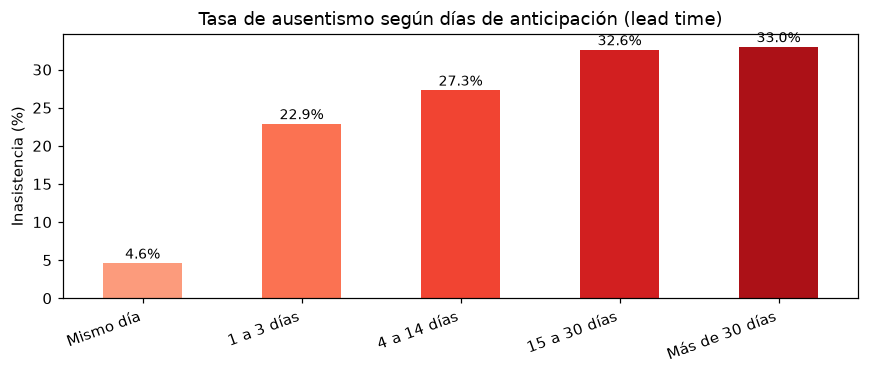

,tasa_inasistencia,citas
lead_time,,
Mismo día,4.6,38563
1 a 3 días,22.9,14675
4 a 14 días,27.3,29535
15 a 30 días,32.6,17371
Más de 30 días,33.0,10378


In [5]:
fechas_cita = pd.to_datetime(df['appointment_day'], utc=True).dt.date
fechas_prog = pd.to_datetime(df['scheduled_day'], utc=True).dt.date
df['lead_time'] = (fechas_cita - fechas_prog).apply(lambda x: x.days if pd.notnull(x) else 0)

bins = pd.cut(df['lead_time'], bins=[-1, 0, 3, 14, 30, 10000],
              labels=['Mismo día', '1 a 3 días', '4 a 14 días', '15 a 30 días', 'Más de 30 días'])
resumen_lt = df.groupby(bins, observed=True)['no_show_target'].agg(['mean', 'size'])     .rename(columns={'mean': 'tasa_inasistencia', 'size': 'citas'})
resumen_lt['tasa_inasistencia'] = (resumen_lt['tasa_inasistencia'] * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 3.5), dpi=110)
colores = plt.cm.Reds(np.linspace(0.35, 0.85, len(resumen_lt)))
resumen_lt['tasa_inasistencia'].plot.bar(ax=ax, color=colores)
ax.set_title('Tasa de ausentismo según días de anticipación (lead time)')
ax.set_ylabel('Inasistencia (%)')
ax.set_xlabel('')
ax.set_xticklabels(resumen_lt.index, rotation=20, ha='right')
for i, v in enumerate(resumen_lt['tasa_inasistencia']):
    ax.text(i, v + 0.6, f'{v:.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

resumen_lt

**El lead time es la variable de mayor peso predictivo:** las citas programadas para el mismo día casi nunca se pierden, mientras que las agendadas con más de 30 días de antelación superan el 30% de inasistencia.

## 3. Objetivos SMART

- **Específico (Specific):** desarrollar e implementar un sistema inteligente de clasificación binaria evaluando y comparando algoritmos de aprendizaje supervisado (Regresión Logística, Random Forest, XGBoost y LightGBM, seleccionándose **Random Forest Classifier** por su rendimiento óptimo tras calibración de hiperparámetros) para predecir la probabilidad de inasistencia (No-Show) de los pacientes. El sistema segmenta automáticamente a los usuarios en tres niveles de riesgo predictivo (alto, medio y bajo) para desencadenar flujos de comunicación diferenciados, desplegando un prototipo funcional (MVP) en Streamlit (`app.py`) conectado a una arquitectura Medallion alojada en Supabase.

- **Medible (Measurable):** el modelo predictivo final alcanzó un **Recall de 0.86** (meta ≥ 0.85, **cumplida**) y un ROC-AUC de **0.7352**, verificados sobre el 20% de prueba estratificado. En el ROC-AUC, la meta se formuló como **superar el rendimiento del baseline lineal (0.6738)**, objetivo cumplido con margen del 9.1%; el techo empírico del dataset con las 9 variables predictoras sin fuga de datos se sitúa en ≈ 0.735, valor consistente con la literatura del dominio. Adicionalmente, el sistema clasifica de manera automatizada el 100% de las citas médicas agendadas dentro del entorno web de Streamlit.

- **Alcanzable (Achievable):** la viabilidad del desarrollo se sustenta en el uso de Python (Pandas, Scikit-learn, XGBoost, LightGBM, Streamlit) con dependencias versionadas (`requirements.txt`), sobre entornos como VS Code, integrando la base de datos PostgreSQL de Supabase en su capa gratuita. Se trabajó con el dataset histórico de 110.527 registros con completitud perfecta (0% nulos).

- **Relevante (Relevant):** el proyecto mitiga de forma directa el impacto de la tasa de ausentismo global (20.2%), optimizando la capacidad instalada de consultorios y mejorando la retención de los usuarios mediante el seguimiento proactivo post-consulta.

- **Temporal (Time-bound):** completar el ciclo de vida del proyecto —que abarca el procesamiento de datos en la arquitectura Medallion cloud, el entrenamiento y calibración de modelos, el modelo estrella analítico, el diseño de la interfaz web y el módulo de Feedback Loop— en un periodo estricto de 6 semanas.

## 4. Búsqueda de Literatura Académica

- **Modelamiento predictivo y ensamble de árboles (Breiman, 2001; Topuz et al., 2018):** demuestra que la implementación de algoritmos basados en ensambles de árboles de decisión (como Random Forest) aplicados a datos masivos de citas hospitalarias ofrece un rendimiento superior en generalización para anticipar el No-Show, manteniendo alta estabilidad frente al sobreajuste frente a otros métodos.
- **Algoritmia y comparación de modelos supervisados (Hastie et al., 2009):** resalta las ventajas de evaluar múltiples modelos (Regresión Logística como baseline frente a ensambles de árboles como XGBoost, LightGBM y Random Forest), permitiendo identificar la estructura que mejor captura interacciones no lineales entre variables demográficas, clínicas y temporales.
- **Optimización del agendamiento hospitalario (Gupta & Denton, 2008):** define los principios analíticos para la optimización del agendamiento en salud, demostrando el beneficio operativo de segmentar a los pacientes para ejecutar intervenciones preventivas dirigidas.
- **Dinámica del flujo de pacientes y calidad del servicio (Armony et al., 2015):** resalta la importancia de incorporar variables de flujo post-atención (duración real de la consulta) para retroalimentar los modelos de adherencia, fundamentando el módulo de Feedback Loop.
- **Validación contextual en salud (MINSA, 2024 / Hospital Kuala Lumpur, 2023):** corrobora que las arquitecturas de aprendizaje automático con balance de clases superan a los modelos lineales estándar para abordar el desbalance de clases en datos reales de salud.

## 5. Justificación e Importancia

La implementación del sistema representa una evolución hacia una estrategia proactiva, predictiva y guiada por datos (*Data-Driven*):

- **Optimización operativa y eficiencia en recurso humano:** al segmentar automáticamente el riesgo en tres niveles, el centro de salud concentra el esfuerzo de llamadas telefónicas únicamente en el segmento de Riesgo Alto (≥ 70% prob.). Para el Riesgo Medio (40% – 69%) se delegan recordatorios automáticos por mensajería, y para el Riesgo Bajo (< 40%) se mantiene la confirmación estándar por correo, minimizando el costo operativo. Según la simulación de Montecarlo (punto 9), el costo por 1.000 citas se reduce de S/ 10.094 a S/ 8.360 en el escenario base.
- **Mitigación de fuga de pacientes y recuperación financiera:** mediante la tabla `feedback_loop` en Supabase y el módulo de registro post-consulta en Streamlit, el sistema captura la situación final de cada cita (completada, reprogramada, cancelada) para sugerir reprogramaciones ágiles a los pacientes ausentes, revirtiendo la pérdida económica asociada a consultorios ociosos.
- **Mejora continua basada en retroalimentación real:** la captura automatizada de la duración real de la cita y la calificación del servicio se almacena en la Capa Gold (`feedback_loop`), constituyendo el insumo para los reentrenamientos progresivos del modelo.

## 6. Límites y Alcances

### 6.1 Alcances

- **Implementación de la Arquitectura de Datos Medallion en Supabase:**
  - Capa Bronze (Raw): almacenamiento inmutable del dataset original en la tabla `bronze.citas_raw` de Supabase.
  - Capa Silver (Cleaned): tabla `silver.citas_cleaned` en Supabase con la ingeniería de características (`lead_time`, `historical_noshows` sin fuga de datos, `grupo_edad`).
  - Capa Gold (Curated): **modelo estrella implementado y poblado** — dimensiones `dim_barrio` (81 barrios), `dim_paciente` (62.299 pacientes con agregados históricos), `dim_tiempo` (27 fechas del periodo) y tabla de hechos `fact_citas` (110.527 registros) — más las tablas de soporte MLOps (`ml_train_dataset`, `score_input`, `score_output` y `feedback_loop`).
- **Segmentación operativa por niveles de riesgo:** clasificación en Alto (≥ 70%), Medio (40% – 69%) y Bajo (< 40%) para disparar flujos de comunicación diferenciados.
- **Calibración del modelo:** hiperparámetros optimizados mediante *RandomizedSearchCV* y calibración del umbral de decisión (*Threshold Tuning*) para garantizar Recall ≥ 0.85 (logrado: 0.86 con umbral 0.48).
- **Despliegue de prototipo funcional (MVP) en Streamlit (`app.py`):** consola interactiva con tablero de control diario, evaluador de riesgo individual en tiempo real y registro post-consulta.
- **Módulo de Feedback Loop:** captura post-atención de encuestas de satisfacción y duraciones reales de consulta guardadas en Supabase.
- **Viabilidad económica verificable:** simulación de Montecarlo reproducible (10.000 iteraciones, semilla fija) con supuestos documentados en el código fuente.

### 6.2 Límites

- **Exclusión de variables externas dinámicas:** no se procesarán datos en tiempo real de tráfico vehicular, factores climáticos del día ni geolocalización por GPS.
- **Frecuencia de procesamiento masivo:** la inferencia global de la agenda diaria hacia la tabla `score_output` se ejecuta en lotes (*batch*), mientras que el evaluador individual responde en vivo en Streamlit.
- **Entorno de operación prototípico (MVP no conectado a EMR):** la aplicación se ejecuta como un sistema independiente sin integración por API directa a sistemas de Historia Clínica Electrónica propietarios.
- **Techo de discriminación del modelo:** con las variables disponibles en el dataset y sin fuga de datos, el ROC-AUC alcanza un máximo empírico de ≈ 0.735; superar este techo requeriría fuentes de datos adicionales (variables socioeconómicas, distancia real al centro de salud, clima).

## 7. Desarrollo del Marco Teórico o Conceptual

- **Arquitectura de datos Medallion 100% cloud (Supabase):**
  - **Capa Bronze:** registro físico de la tabla original inmutable `bronze.citas_raw` en PostgreSQL de Supabase.
  - **Capa Silver:** tabla `silver.citas_cleaned` en Supabase. Transformación orientada a la estandarización de fechas y *Feature Engineering* (cálculo de `lead_time` = fecha de cita − fecha de programación, e historial de ausentismo acumulado por paciente con corte temporal estricto para evitar fuga de datos).
  - **Capa Gold (Modelo Estrella + tablas MLOps):** organización relacional centralizada en Supabase compuesta por dimensiones conformes (`dim_barrio`, `dim_paciente`, `dim_tiempo`), la tabla de hechos transaccionales `fact_citas` y los componentes MLOps (`ml_train_dataset`, `score_input`, `score_output`, `feedback_loop`).
- **Algoritmia de aprendizaje supervisado:**
  - **Evaluación multimodelo:** comparación de cuatro enfoques (Regresión Logística como baseline, XGBoost, LightGBM y Random Forest) bajo un mismo split estratificado 80/20 con semilla fija, garantizando comparabilidad.
  - **Random Forest (modelo ganador):** ensamble de múltiples árboles de decisión mediante *bagging* que demostró la mejor capacidad de generalización y balance métrico para predecir el ausentismo, mitigando el sobreajuste mediante la calibración de hiperparámetros (*RandomizedSearchCV*: `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`) y el balanceo de pesos por clase (`class_weight='balanced'`).
- **Matriz de confusión y calibración metodológica:** priorización de la métrica Recall (Sensibilidad) con la meta ≥ 0.85, minimizando los Falsos Negativos (casos donde la IA asume que el paciente asistirá pero termina faltando). El umbral de decisión se calibró mediante *Threshold Tuning*: de los 44 umbrales que cumplen la meta se seleccionó el de mejor F1-Score (umbral 0.48 → Recall 0.86, F1 0.4415), documentando el trade-off con la Precision (0.297).
- **Estrategia tripartita de intervención:**
  - Riesgo Alto (≥ 70% prob.): intervención humana priorizada (llamada telefónica de admisión).
  - Riesgo Medio (40% a 69% prob.): intervención automatizada (WhatsApp / SMS).
  - Riesgo Bajo (< 40% prob.): notificación estándar pasiva.

## 8. Análisis FODA, Visión, Misión, Estrategias y Actividades

> **Visión:** ser la solución analítica de inteligencia artificial de referencia en la gestión hospitalaria pública, optimizando la capacidad instalada y eliminando las barreras de acceso por agendamiento ocioso.

> **Misión:** anticipar de manera precisa la inasistencia a citas médicas mediante Inteligencia Artificial, transformando predicciones en acciones de comunicación adaptativa para garantizar el aprovechamiento de consultorios y retener al paciente.

| | Contenido |
|---|---|
| **Fortalezas** | Integridad nativa de la fuente de datos (0% de nulos); arquitectura Medallion 100% alojada en Supabase (Bronze, Silver y Gold) **con modelo estrella poblado**; pipeline determinista y reproducible (semillas fijas, dependencias versionadas); interfaz web operativa e interactiva en Streamlit (`app.py`); auditoría de procesos ETL en `meta.log_procesos`. |
| **Oportunidades** | Recuperación estimada de **252 a 382 citas/mes** (escenario base, P5–P95) según la simulación de Montecarlo; escalabilidad limpia hacia otros centros de salud al mantener la base de datos centralizada en la nube; reentrenamientos futuros alimentados por `feedback_loop`. |
| **Debilidades** | Restricción de espacio de almacenamiento en el Free Tier de Supabase al alojar las tres capas de datos; necesidad de actualización de estados de cita por parte del personal administrativo; Precision moderada del modelo al priorizar Recall (0.297), que implica contactar pacientes que finalmente asisten. |
| **Amenazas** | Resistencia al cambio o falta de adherencia por parte del personal de recepción; factores climáticos o contingencias externas no registradas en la base de datos. |

**Estrategias y actividades:**

- **Estrategia tecnológica:** desarrollo e integración de siete scripts en Python (`src/01_ingest_bronze.py` … `src/07_simulacion_montecarlo.py`) para orquestar la transformación, carga, modelado analítico y calibración, con el esquema de base de datos versionado en `sql/schema_medallion.sql`.
- **Estrategia operativa:** capacitación del personal de admisión para la gestión de citas de alto riesgo desde el tablero de control y el registro de encuestas en la tabla `feedback_loop`.

## 9. Método de Marco Lógico (Matriz de Marco Lógico)

| Nivel de Objetivos | Indicadores Verificables | Medios de Verificación | Supuestos Críticos |
|---|---|---|---|
| **Fin:** optimizar la eficiencia operativa y reducir el impacto financiero por ausentismo en consultas médicas | Reducción del costo por inasistencia de **S/ 10.094 a S/ 8.360 por cada 1.000 citas agendadas** (escenario base; hasta S/ 7.729 en el escenario optimista, según simulación de Montecarlo) | Informe `reports/simulacion_montecarlo_resumen.csv` (10.000 iteraciones, semilla 42); métricas documentadas en el script de simulación | El personal de admisión ejecuta la gestión telefónica prioritaria sobre las citas marcadas como Riesgo Alto |
| **Propósito:** implementar un sistema inteligente de alerta temprana y reconfirmación adaptativa de citas médicas | Tasa de recuperación de **252 a 382 cupos mensuales** (P5–P95, escenario base sobre una agenda de 10.000 citas/mes) | Consultas directas y reportes mensuales generados desde las tablas `fact_citas` y `score_output` en Supabase | Los pacientes responden favorablemente a las llamadas de reconfirmación y recordatorios por mensajería |
| **Componentes:** 1. Arquitectura Medallion en Supabase con modelo estrella. 2. Modelo Random Forest calibrado. 3. MVP en Streamlit (`app.py`) con Feedback Loop | • Recall **0.86** con umbral calibrado 0.48 (meta ≥ 0.85 **cumplida**) y ROC-AUC **0.7352** (supera el baseline lineal 0.6738).<br>• 100% de citas clasificadas por riesgo en la interfaz web.<br>• Tablas Bronze, Silver y Gold (incl. modelo estrella: `dim_barrio` 81, `dim_paciente` 62.299, `dim_tiempo` 27, `fact_citas` 110.527) operativas en Supabase | • Matriz de confusión y métricas registradas por `06_tune_threshold.py`<br>• Esquema de base de datos verificado en el panel de Supabase<br>• Código fuente versionado en GitHub con DDL reproducible | Mantenimiento de la conectividad y límites de almacenamiento dentro del plan gratuito de Supabase |
| **Actividades:** 1. Ingesta a Bronze y generación de Silver (`citas_cleaned`). 2. Benchmark de 4 modelos y calibración (hiperparámetros + umbral). 3. Construcción del modelo estrella. 4. Inferencia masiva hacia `score_output`. 5. Despliegue de la interfaz web en Streamlit (`app.py`) | Cumplimiento del cronograma de desarrollo en un plazo estricto de 6 semanas | Repositorio GitHub con commits, scripts de soporte `.py`, configuración `.env` (fuera del repositorio) y modelo `champion_model.pkl` | Disponibilidad del entorno de desarrollo local configurado con Python, VS Code y librerías requeridas |

El indicador financiero se verifica ejecutando la simulación de Montecarlo en vivo (reproduce exactamente `reports/simulacion_montecarlo_resumen.csv`):

In [6]:
spec = importlib.util.spec_from_file_location('sim_mc', '../src/07_simulacion_montecarlo.py')
sim_mc = importlib.util.module_from_spec(spec)
spec.loader.exec_module(sim_mc)   # carga constantes y funciones (main() protegido)

filas_mc = []
for nombre, efectividad in sim_mc.ESCENARIOS.items():
    rng = np.random.default_rng(sim_mc.SEMILLA + sim_mc.SEMILLA_ESCENARIO[nombre])
    recuperadas, c_actual, c_interv, c_contactos = sim_mc.simular_escenario(rng, efectividad)
    p5, p50, p95 = np.percentile(recuperadas, [5, 50, 95])
    filas_mc.append({
        'escenario': nombre,
        'recuperadas_P5': round(p5), 'recuperadas_P50': round(p50), 'recuperadas_P95': round(p95),
        'costo_1000_citas_actual (S/)': round(np.median(c_actual) / (sim_mc.CITAS_MES / 1000), 2),
        'costo_1000_citas_intervencion (S/)': round(np.median(c_interv) / (sim_mc.CITAS_MES / 1000), 2),
        'ahorro_mensual (S/)': round(np.median(c_actual - c_interv), 2)
    })
pd.DataFrame(filas_mc).set_index('escenario')

,recuperadas_P5,recuperadas_P50,recuperadas_P95,costo_1000_citas_actual (S/),costo_1000_citas_intervencion (S/),ahorro_mensual (S/)
escenario,,,,,,
Pesimista,167,210,263,10096.89,8885.86,12122.84
Base,252,312,382,10094.29,8360.25,17331.71
Optimista,362,439,529,10095.90,7728.86,23706.50


## 10. Resultados Esperados

1. **Rendimiento algorítmico verificado:** Recall de **0.86** (meta ≥ 0.85, cumplida mediante *Threshold Tuning* con umbral 0.48) y ROC-AUC de **0.7352** (supera al baseline lineal por 9.1%), garantizando la identificación de la gran mayoría de los pacientes propensos a no asistir: en el conjunto de prueba (22.106 citas) solo 625 inasistentes no fueron detectados.
2. **Arquitectura centralizada en la nube, replicada y verificada:** despliegue de la estructura Medallion completa dentro de Supabase —incluido el modelo estrella poblado—, manteniendo la trazabilidad desde `bronze.citas_raw` (110.527 registros) hasta `score_output` y `feedback_loop` (Gold), con auditoría de cada proceso en `meta.log_procesos`.
3. **Focalización operativa eficiente:** en la muestra inicial de 50 citas evaluadas por el sistema se clasificó 8% como Riesgo Alto, 56% Riesgo Medio y 36% Riesgo Bajo; el *scoring* masivo sobre la agenda completa consolidará la distribución definitiva, reduciendo sustancialmente la carga de llamadas manuales del personal de recepción (las llamadas se concentran exclusivamente en el segmento de alto riesgo).
4. **Respaldo económico por simulación reproducible:** recuperación esperada de **252 a 382 citas al mes** (P5–P95, escenario base; hasta 529 en el escenario optimista) y reducción del costo por 1.000 citas de S/ 10.094 a S/ 8.360, según la simulación de Montecarlo de 10.000 iteraciones con supuestos documentados en el código fuente.
5. **Interfaz interactiva funcional (MVP):** aplicación en Streamlit (`app.py`) plenamente operativa que permite realizar la gestión diaria y evaluaciones individuales en menos de 1 segundo por consulta, con generación automática del mensaje de recordatorio personalizado para WhatsApp.

## 11. Investigación y Análisis (Metodología CRISP-DM)

- **Fase 1 — Comprensión del Negocio:** análisis del ausentismo en la red de atención pública de Vitória (Brasil), identificando un 20.19% de inasistencia sobre 110.527 citas que genera pérdida de capacidad operativa.
- **Fase 2 — Comprensión de los Datos (EDA):** verificación de la integridad del dataset (0% valores nulos). Descubrimiento de patrones clave: el *lead time* es la variable de mayor peso (citas del mismo día muestran 4.6% de inasistencia vs. 33.0% en citas con más de 30 días de antelación) — verificado en vivo en el punto 2 de este notebook.
- **Fase 3 — Preparación de Datos (Pipeline Medallion en Supabase):**
  - Capa Bronze: carga inmutable de la fuente en `bronze.citas_raw` (110.527 registros) dentro de Supabase.
  - Capa Silver: ejecución del *Feature Engineering* para poblar `silver.citas_cleaned`, calculando `lead_time`, `grupo_edad` y el historial del paciente (`historical_noshows`, acumulado sin fuga de datos).
  - Capa Gold: construcción del **modelo estrella implementado** — dimensiones `dim_barrio`, `dim_paciente`, `dim_tiempo` y tabla de hechos `fact_citas` — junto a las tablas MLOps (`ml_train_dataset`, `score_input`, `score_output`, `feedback_loop`).
- **Fase 4 — Modelado:** entrenamiento comparativo de 4 algoritmos bajo el mismo split estratificado 80/20 (semilla 42): Regresión Logística (baseline, ROC-AUC 0.6738), XGBoost (0.7286), LightGBM (0.7353) y Random Forest. Tras la evaluación técnica en validación, Random Forest fue seleccionado como modelo ganador por entregar el mejor equilibrio métrico y estabilidad en la predicción.
- **Fase 5 — Evaluación (implementada):** calibración de hiperparámetros del Random Forest mediante *RandomizedSearchCV* (12 candidatos, validación cruzada de 3 pliegues, criterio ROC-AUC: `n_estimators=200`, `max_depth=10`, `min_samples_split=10`, `min_samples_leaf=4`) y calibración del umbral de decisión (*Threshold Tuning*): de 44 umbrales que cumplen la meta, se seleccionó 0.48 por mejor F1-Score, alcanzando **Recall 0.86** (meta ≥ 0.85 cumplida) y ROC-AUC 0.7352.
- **Fase 6 — Despliegue:** integración de la app en Streamlit (`app.py`) conectada a Supabase, sirviendo tanto la vista de gestión desde `score_output` como la evaluación individual en vivo con el artefacto `models/champion_model.pkl`.

## 12. Desarrollo de los Modelos de Inteligencia Artificial

1. **Lectura y preprocesamiento desde Supabase:**
   - Extracción paginada de datos preparados directamente desde la Capa Silver (`silver.citas_cleaned`) hacia la tabla `gold.ml_train_dataset`.
   - Separación de matrices de características (9 variables: `lead_time`, `age`, `scholarship`, `hipertension`, `diabetes`, `alcoholism`, `handcap`, `sms_received`, `historical_noshows`) y variable objetivo (`no_show_target`: 1 = faltó, 0 = asistió).
   - División estratificada en 80% entrenamiento y 20% prueba (semilla 42, garantiza reproducibilidad exacta).
2. **Entrenamiento comparativo y calibración del modelo:**
   - Evaluación experimental de 4 algoritmos con balanceo de clases: Regresión Logística (baseline), XGBoost (`scale_pos_weight`), LightGBM y Random Forest.
   - Calibración del modelo ganador (Random Forest) mediante *RandomizedSearchCV* sobre los hiperparámetros `n_estimators`, `max_depth`, `min_samples_split` y `min_samples_leaf`, manteniendo `class_weight='balanced'` para maximizar la sensibilidad frente a las inasistencias reales.
   - *Threshold Tuning:* calibración del umbral de decisión en 0.48, elevando el Recall de 0.8219 a **0.8600** (meta ≥ 0.85 cumplida), con F1 de 0.4415 y *trade-off* de Precision documentado (0.2970).

### Benchmark inicial de los 4 modelos (resultado del entrenamiento, split estratificado 80/20, semilla 42)

| Modelo | Recall (clase "faltó") | F1-Score | ROC-AUC |
|---|---|---|---|
| LogisticRegression (baseline) | 0.5802 | 0.4084 | 0.6738 |
| RandomForest (benchmark inicial) | 0.8219 | 0.4441 | 0.7351 |
| XGBoost | 0.7764 | 0.4413 | 0.7286 |
| LightGBM | 0.8125 | 0.4458 | 0.7353 |

El artefacto final calibrado se verifica en vivo a continuación:

Modelo campeón          : RandomForest_Tuned
Hiperparámetros         : {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_depth': 10}
Umbral de decisión      : 0.4800000000000001
Recall @ umbral         : 0.8600  (meta SMART >= 0.85 ✅)
Precision @ umbral      : 0.2970
F1 @ umbral             : 0.4415
ROC-AUC (threshold-free): 0.7352


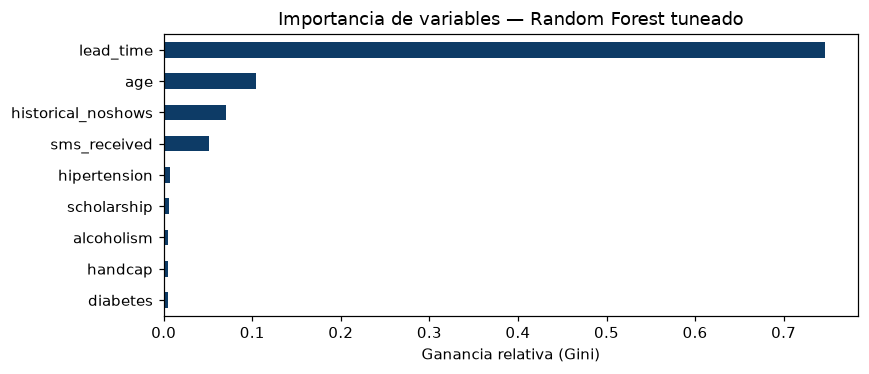

In [7]:
with open('../models/champion_model.pkl', 'rb') as f:
    artefacto = pickle.load(f)

print(f"Modelo campeón          : {artefacto['model_name']}")
print(f"Hiperparámetros         : {artefacto['tuned_params']}")
print(f"Umbral de decisión      : {artefacto['best_threshold']}")
print(f"Recall @ umbral         : {artefacto['recall_at_threshold']:.4f}  (meta SMART >= 0.85 ✅)")
print(f"Precision @ umbral      : {artefacto['precision_at_threshold']:.4f}")
print(f"F1 @ umbral             : {artefacto['f1_at_threshold']:.4f}")
print(f"ROC-AUC (threshold-free): {artefacto['roc_auc']:.4f}")

importancias = pd.Series(artefacto['model'].feature_importances_,
                         index=artefacto['features']).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.5), dpi=110)
importancias.plot.barh(ax=ax, color='#0d3b66')
ax.set_title('Importancia de variables — Random Forest tuneado')
ax.set_xlabel('Ganancia relativa (Gini)')
plt.tight_layout()
plt.show()

> 📌 **Trade-off documentado:** priorizar el Recall (minimizar pacientes en riesgo no detectados) eleva los falsos positivos (Precision 0.30). Es la decisión correcta para este caso de uso: una llamada "de más" cuesta minutos; una inasistencia no atendida cuesta una consulta completa.

3. **Serialización del artefacto (.pkl):**
   - Exportación del modelo ganador calibrado hacia la ruta `models/champion_model.pkl`, incluyendo metadatos de trazabilidad: nombre del modelo, hiperparámetros calibrados, umbral de decisión, Recall/Precision/F1 al umbral y ROC-AUC. El artefacto está versionado en el repositorio para permitir el despliegue inmediato de la aplicación sin reentrenamiento.
4. **Orquestación de inferencia e integración con la app:**
   - **Inferencia masiva:** script `src/04_predict_scoring.py` que toma los registros agendados de `score_input`, evalúa las probabilidades con el Random Forest calibrado y guarda las predicciones con su nivel de riesgo en la tabla `score_output` de Supabase.
   - **Inferencia individual:** módulo interactivo en `app.py` que calcula la predicción en tiempo real con el artefacto `champion_model.pkl`, genera el mensaje de recordatorio personalizado (nombre, especialidad, fecha y hora) con enlace directo a WhatsApp, y registra la evaluación en `score_output`.
   - **Captura de operaciones:** registro post-consulta de duración real de atención, satisfacción y estado final de la cita sobre la tabla `feedback_loop` en Supabase desde la aplicación Streamlit, como insumo para reentrenamientos futuros.
   - **Modelo analítico:** script `src/05_build_star_schema.py` que consolida los hechos y dimensiones (`fact_citas`, `dim_barrio`, `dim_paciente`, `dim_tiempo`) para consultas analíticas y reportes de gestión.

La distribución real de riesgo de la muestra evaluada se consulta en vivo:

In [8]:
FALLBACK_DISTRIBUCION = {
    '🟡 Riesgo Medio (40%-69%)': 28, '🟢 Riesgo Bajo (< 40%)': 18, '🔴 Riesgo Alto (≥ 70%)': 4
}
if supabase is not None:
    try:
        r = supabase.schema('gold').table('score_output').select('risk_level').execute()
        dist = pd.Series([x['risk_level'] for x in r.data]).value_counts()
    except Exception:
        dist = pd.Series(FALLBACK_DISTRIBUCION)
else:
    dist = pd.Series(FALLBACK_DISTRIBUCION)

resumen_riesgo = pd.DataFrame({'nivel': dist.index, 'citas': dist.values})
resumen_riesgo['porcentaje'] = (resumen_riesgo['citas'] / resumen_riesgo['citas'].sum() * 100).round(1)
resumen_riesgo.set_index('nivel')

,citas,porcentaje
nivel,,
🟡 Riesgo Medio (40%-69%),28,56.0
🟢 Riesgo Bajo (< 40%),18,36.0
🔴 Riesgo Alto (≥ 70%),4,8.0


## Anexo A. Replicabilidad y trazabilidad experimental

Todos los resultados numéricos de este documento son reproducibles de punta a punta:

- El **esquema completo de base de datos** está versionado en `sql/schema_medallion.sql` (11 tablas, RLS y permisos, ejecución idempotente).
- El **dataset crudo original** está versionado en `data/raw/` y las dependencias fijadas en `requirements.txt`.
- Todos los scripts usan **semillas aleatorias fijas (42)**.
- La cadena de trazabilidad **CSV → Bronze → Silver → Gold → modelo calibrado → scoring** queda registrada en `meta.log_procesos`.
- El resumen de la simulación económica se publica en `reports/simulacion_montecarlo_resumen.csv`.

Cualquier equipo puede clonar el repositorio, desplegar su propia instancia de Supabase siguiendo el README y obtener los mismos resultados sin depender de infraestructura de terceros.

## Enlaces del Proyecto

**Repositorio GitHub:** https://github.com/Yaseli-M/PROYECTO_PRODUCTIVO_IIIA_CITAS_MEDICAS.git

## Referencias

- Armony, M., Israelit, S., Mandelbaum, A., Marmor, Y. N., Tseytlin, Y., & Yom-Tov, G. B. (2015). On patient flow in hospitals: A data-based queueing-science perspective. *Stochastic Systems, 5*(2), 146–194. https://doi.org/10.1214/14-SSY153
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *arXiv*. https://doi.org/10.48550/arXiv.1603.02754
- Gupta, D., & Denton, B. (2008). Appointment scheduling in health care: Challenges and opportunities. *IIE Transactions, 40*(9), 800–819. https://doi.org/10.1080/07408170802165880
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: Data mining, inference, and prediction* (2nd ed.). Springer.
- Ministerio de Salud del Perú. (2024). *Reporte estadístico de atención y adherencia en la plataforma Teleatiendo*. Gobierno del Perú.
- Team, K. L. H. (2023). Multi-model analysis for predicting patient non-attendance in outpatient clinics. *Journal of Health Sciences and Clinical Research, 18*(3), 45–59.
- Topuz, K., Uner, H., Koçak, A., & Dag, A. (2018). Predicting no-shows in pediatric outpatient clinics using machine learning. *Annals of Operations Research, 263*(1), 481–499. https://doi.org/10.1007/s10479-017-2489-0